In [1]:
import torch
import torch.utils.data as data_utils
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import hiddenlayer as hl
from torchtext.data import Field, BucketIterator, TabularDataset, LabelField
import torchtext
import torchtext.vocab as vocab
from nltk import word_tokenize
import random
import re

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline

# Binary Text Classification
- Steps:
    - tokenize: split text into words
    - encode word as a number (Wn -> Xn)
        - assign unique identifier for each word in the text corpus
        - represents word index locations in the one-hot vector representation of words
        - low dimensionality encoding of input words
    - aggregate as a tensor: d = [x0, x1, ..xn]
        - vector of unique identifiers (index location in the vocab)
    - pre-processing
        - input has the same length, equal to the RNN layer count
        - use padding/truncation to equalize the length
        - each word is fed into the RNN at a time-sequence
        - special tokens:
            - pad for padding
            - unk for words not in the vocab of training data
    - convert numerical ids into word embeddings
    - feed embeddings into RNN
- embedding methods:
    - One-hot: 
        - create a vocab consisting of all the words in the corpus
        - size of feature vector = size of the vocab
        - use one hot encoding to indicate presence or absence of word
    - frequency-based:
        - indicate how often a word occurs in one text doc
        - count vectors, tfidf vectors
    - co-occurence matrix: similar words will appear together
    - prediction-based:
        - low-dimensional numeric representations that capture meaning and semantic relationships within the context
        - trained through ML techniques (unsupervised) using large corpus of data
        - Word2Vec (Google)
        - GloVe (Stanford) - use word-word co-occurence matrix, NN for relationships
        - general principle: 
            - given the word, predict words in context, or vice versa
            - thus encode each word as a vector of other words
            - way to encode words by capturing the surrounding context
- torchtext:
    - utility package for processing text in PyTorch, specifically for processing NLP
        - torchtext.data: fields, iterators (batch processing), pipelines (preprocessing)
        - torchtext.datasets: sentiment analysis, seq tagging, etc.
        - .vocab: GloVe, CharNGram
        - .utils: download_from_url
    - feed in raw data (csv, json, txt), point to directories
    - use fields to feature select and preprocess
    - automatically generate dataset


In [2]:
df_spam = pd.read_csv(r"D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\ham-spam\spam.csv", 
                      encoding='latin-1')
df_spam.describe().transpose()

,count,unique,top,freq
v1,5572,2,ham,4825
v2,5572,5169,"Sorry, I'll call later",30
Unnamed: 2,50,43,"bt not his girlfrnd... G o o d n i g h t . . .@""",3
Unnamed: 3,12,10,"MK17 92H. 450Ppw 16""",2
Unnamed: 4,6,5,"GNT:-)""",2


In [3]:
df_spam.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df_spam = df_spam.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)
df_spam = df_spam.rename(columns={'v1': 'labels', 'v2': 'text'})
df_spam.describe().transpose()

,count,unique,top,freq
labels,5572,2,ham,4825
text,5572,5169,"Sorry, I'll call later",30


In [5]:
train, test = train_test_split(df_spam, test_size=0.2, random_state=42)
train.reset_index(drop=True, inplace=True), test.reset_index(drop=True, inplace=True)
train.shape, test.shape

((4457, 2), (1115, 2))

In [6]:
TEXT = Field(tokenize=word_tokenize)
LABEL = LabelField(dtype=torch.float)

datafields = [('labels', LABEL), ('text', TEXT)]

In [7]:
trn, tst = TabularDataset.splits(path=r"D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\ham-spam",
                                 train="train.csv", 
                                 test="test.csv", 
                                 format='csv',
                                 skip_header=True, 
                                 fields=datafields)

In [8]:
trn[5].__dict__.keys()

dict_keys(['labels', 'text'])

In [9]:
len(trn), len(tst)

(4457, 1115)

In [11]:
print(trn[5].text)
print(trn[5].labels)
print(vars(trn[5]))

['G', 'says', 'you', 'never', 'answer', 'your', 'texts', ',', 'confirm/deny']
ham
{'labels': 'ham', 'text': ['G', 'says', 'you', 'never', 'answer', 'your', 'texts', ',', 'confirm/deny']}


In [12]:
TEXT.build_vocab(trn, max_size=10500)
LABEL.build_vocab(trn)
print(len(TEXT.vocab))
print(TEXT.vocab.freqs.most_common(10))
print(len(LABEL.vocab))

10196
[('.', 3862), ('to', 1750), ('I', 1574), (',', 1468), ('you', 1462), ('?', 1256), ('!', 1134), ('a', 1068), ('the', 946), ('...', 923)]
2


In [13]:
print(TEXT.vocab.itos[:10])
print(LABEL.vocab.stoi)

['<unk>', '<pad>', '.', 'to', 'I', ',', 'you', '?', '!', 'a']
defaultdict(None, {'ham': 0, 'spam': 1})


In [14]:
batch_size = 64

train_iterator, test_iterator = BucketIterator.splits(
    (trn, tst),
    batch_size=batch_size,
    sort_key=lambda x: len(x.text),
    sort_within_batch=False,
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

In [15]:
class RNN(nn.Module):
    def __init__(self, input_dim, embedding_dim, hidden_dim, output_dim):
        super().__init__()

        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.rnn = nn.RNN(embedding_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text):

        embedded = self.embedding(text)
        output, hidden = self.rnn(embedded)
        hidden_1D = hidden.squeeze(0)
        assert torch.equal(output[-1, :, :], hidden_1D)

        return self.fc(hidden_1D)

In [16]:
input_dim = len(TEXT.vocab)
embedding_dim = 100
hidden_dim = 256
output_dim = 1

model = RNN(input_dim, embedding_dim, hidden_dim, output_dim)
optimizer = optim.Adam(model.parameters(), lr=1e-6)
criterion = nn.BCEWithLogitsLoss()

In [19]:
def binary_accuracy(preds, y):
    """
    Returns accuracy per batch for binary classification
    """
    # Round predictions to the closest integer (0 or 1)
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()  # Convert into float for division
    acc = correct.sum() / len(correct)
    return acc

def train(model, iterator, optimizer, criterion):
    epoch_loss = 0
    epoch_acc = 0

    model.train()

    for batch in iterator:

        optimizer.zero_grad()
        predictions = model(batch.text).squeeze(1)
        loss = criterion(predictions, batch.labels)
        acc = binary_accuracy(predictions, batch.labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc.item()

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [20]:
# training the model
num_epochs = 5

for epoch in range(num_epochs):

    train_loss, train_acc = train(model, train_iterator, optimizer, criterion)

    print(f'Epoch: {epoch+1:02}')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%')

Epoch: 01
	Train Loss: 0.781 | Train Acc: 13.88%
Epoch: 02
	Train Loss: 0.744 | Train Acc: 13.95%
Epoch: 03
	Train Loss: 0.711 | Train Acc: 14.71%
Epoch: 04
	Train Loss: 0.679 | Train Acc: 85.40%
Epoch: 05
	Train Loss: 0.650 | Train Acc: 85.45%


In [21]:
# evaluate the model
epoch_loss = 0
epoch_acc = 0

model.eval()

RNN(
  (embedding): Embedding(10196, 100)
  (rnn): RNN(100, 256)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

In [23]:
with torch.no_grad():
    for batch in test_iterator:

        predictions = model(batch.text).squeeze(1)
        loss = criterion(predictions, batch.labels)
        acc = binary_accuracy(predictions, batch.labels)

        epoch_loss += loss.item()
        epoch_acc += acc.item()

print(f'Test Loss: {epoch_loss/len(test_iterator):.3f} | Test Acc: {epoch_acc/len(test_iterator)*100:.2f}%')

Test Loss: 0.673 | Test Acc: 68.89%


In [24]:
# LSTM model
class LSTM(nn.Module):
    def __init__(self, input_dim, embedding_dim, hidden_dim, output_dim):
        super().__init__()

        self.embedding = nn.Embedding(input_dim, embedding_dim)
        self.rnn = nn.LSTM(embedding_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(0.3)

    def forward(self, text):

        embedded = self.embedding(text)
        embedded = self.dropout(embedded)
        output, (hidden, _) = self.rnn(embedded)
        hidden_1D = hidden.squeeze(0)
        assert torch.equal(output[-1, :, :], hidden_1D)

        return self.fc(hidden_1D)

In [25]:
# training the model
input_dim = len(TEXT.vocab)
embedding_dim = 100
hidden_dim = 256
output_dim = 1

model = LSTM(input_dim, embedding_dim, hidden_dim, output_dim)
optimizer = optim.Adam(model.parameters(), lr=1e-6)
criterion = nn.BCEWithLogitsLoss()

num_epochs = 5

for epoch in range(num_epochs):

    train_loss, train_acc = train(model, train_iterator, optimizer, criterion)

    print(f'Epoch: {epoch+1:02}')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%')

Epoch: 01
	Train Loss: 0.699 | Train Acc: 34.95%
Epoch: 02
	Train Loss: 0.687 | Train Acc: 65.57%
Epoch: 03
	Train Loss: 0.675 | Train Acc: 82.54%
Epoch: 04
	Train Loss: 0.663 | Train Acc: 85.83%
Epoch: 05
	Train Loss: 0.652 | Train Acc: 86.10%


In [26]:
# evaluate the model
epoch_loss = 0
epoch_acc = 0

model.eval()

LSTM(
  (embedding): Embedding(10196, 100)
  (rnn): LSTM(100, 256)
  (fc): Linear(in_features=256, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

In [28]:
with torch.no_grad():
    for batch in test_iterator:

        predictions = model(batch.text).squeeze(1)
        loss = criterion(predictions, batch.labels)
        acc = binary_accuracy(predictions, batch.labels)

        epoch_loss += loss.item()
        epoch_acc += acc.item()

print(f'Test Loss: {epoch_loss/len(test_iterator):.3f} | Test Acc: {epoch_acc/len(test_iterator)*100:.2f}%')

Test Loss: 0.670 | Test Acc: 81.42%


# Multi-class Text Classification

In [2]:
from io import open
import glob
import os

In [3]:
print(glob.glob(r"D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\data\names\*.txt"))

['D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Arabic.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Chinese.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Czech.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Dutch.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\English.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\French.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\German.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Greek.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Irish.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\data\\names\\Italian.txt', 'D:\\PluraSight\\PyTorch\\5 Natural Language Processing\\datasets\\dat

In [3]:
import unicodedata
import string

all_letters = string.ascii_letters + " .,;'"
n_letters = len(all_letters)

print(all_letters)
print(n_letters)

abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ .,;'
57


In [4]:
language_names = {}
all_languages = []

In [5]:
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
        and c in all_letters
    )

print(unicodeToAscii('Émile'))

Emile


In [6]:
def findFiles(path): 
    return glob.glob(path)

In [7]:
total_names = 0

for filename in findFiles(r'D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\data\names\*.txt'):
    language = os.path.splitext(os.path.basename(filename))[0]
    all_languages.append(language)
    read_names = open(filename, encoding='utf-8').read().strip().split('\n')
    names = [unicodeToAscii(line) for line in read_names]
    language_names[language] = names
    total_names += len(names)

In [8]:
all_languages

['Arabic',
 'Chinese',
 'Czech',
 'Dutch',
 'English',
 'French',
 'German',
 'Greek',
 'Irish',
 'Italian',
 'Japanese',
 'Korean',
 'Polish',
 'Portuguese',
 'Russian',
 'Scottish',
 'Spanish',
 'Vietnamese']

In [9]:
n_languages = len(all_languages)
print(n_languages)
print(total_names)

18
20074


In [10]:
print(language_names['Italian'][:5])

['Abandonato', 'Abatangelo', 'Abatantuono', 'Abate', 'Abategiovanni']


In [11]:
def letterToTensor(letter):
    tensor = torch.zeros(1, n_letters)
    tensor[0][all_letters.find(letter)] = 1
    return tensor

print(letterToTensor('J'))

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0.]])


In [12]:
def nameToTensor(name):
    tensor = torch.zeros(len(name), 1, n_letters)
    for li, letter in enumerate(name):
        tensor[li][0][all_letters.find(letter)] = 1
    return tensor

print(nameToTensor('Andrew').size())
print(nameToTensor('Andy'))

torch.Size([6, 1, 57])
tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        

In [13]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(RNN, self).__init__()
        self.hidden_size = hidden_size

        self.i2h = nn.Linear(input_size + hidden_size, hidden_size)
        self.i2o = nn.Linear(input_size + hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, input, hidden):
        combined = torch.cat((input, hidden), 1)
        hidden = self.i2h(combined)
        output = self.i2o(combined)
        output = self.softmax(output)
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, self.hidden_size)
    

In [14]:
n_hidden = 256
rnn = RNN(n_letters, n_hidden, n_languages)

In [15]:
inp = letterToTensor('Z')
hidden = torch.zeros(1, n_hidden)
output, next_hidden = rnn(inp, hidden)

print(output)
import torch.nn.functional as F

# 1. Your rnn returns the raw language scores directly
# output shape is (1, n_languages) or (n_languages,)
output, next_hidden = rnn(inp, hidden)

# 2. Squeeze the output to remove the batch dimension
# (If it's already 1D, squeeze does nothing; if it's 2D, it flattens it to 1D)
output = output.squeeze(0) 

# 3. Apply softmax to get probabilities
probs = F.softmax(output, dim=0)

# 4. Get the highest probability and its index
max_prob, max_index = torch.max(probs, dim=0)

# 5. Map the index to your language
predicted_language = all_languages[max_index.item()]

print(f"Predicted language: {predicted_language}")
print(f"Confidence: {max_prob.item():.4f}")

tensor([[-2.9058, -2.8549, -2.9539, -2.9300, -2.8779, -2.8363, -2.9507, -2.9881,
         -2.8829, -2.8304, -2.8424, -2.8658, -2.8254, -2.9537, -2.8409, -2.8847,
         -2.9215, -2.9021]], grad_fn=<LogSoftmaxBackward0>)
Predicted language: Polish
Confidence: 0.0593


In [16]:
def languageFromOutput(output):
    _, top_i = output.topk(1)  # get the index of the highest probability
    language_i = top_i[0].item()
    return all_languages[language_i], language_i

In [17]:
def randomTrainingExample():
    random_language_index = random.randint(0, n_languages - 1)
    language = all_languages[random_language_index]

    random_language_names = language_names[language]
    name = random_language_names[random.randint(0, len(random_language_names) - 1)]

    language_tensor = torch.tensor([random_language_index], dtype=torch.long)
    name_tensor = nameToTensor(name)
    return language, name, language_tensor, name_tensor

In [18]:
for i in range(10):
    language, name, language_tensor, name_tensor = randomTrainingExample()
    print(f'Language: {language} / Name: {name}')

Language: English / Name: Lovey
Language: Italian / Name: Palumbo
Language: Arabic / Name: Samaha
Language: Japanese / Name: Ieyasu
Language: Vietnamese / Name: Nghiem
Language: English / Name: Rayner
Language: Japanese / Name: Nozara
Language: Czech / Name: Konarik
Language: French / Name: Dufour
Language: Czech / Name: Swatchak


# Sentiment Analysis
- multi-layer RNN: hidden states generated by the bottom RNN layer (h0(t0)) becomes the input for the top layer

In [2]:
glove = torchtext.vocab.GloVe(name='6B', dim=100)
print(f'there are {len(glove.itos)} words in the GloVe vocabulary')
glove.vectors.shape

there are 400000 words in the GloVe vocabulary


torch.Size([400000, 100])

In [3]:
def get_vector(embeddings, word):
    assert word in embeddings.stoi, f"Word '{word}' not found in the embeddings vocabulary."
    return embeddings.vectors[embeddings.stoi[word]]

In [4]:
get_vector(glove, 'hello')

tensor([ 0.2669,  0.3963,  0.6169, -0.7745, -0.1039,  0.2670,  0.2788,  0.3099,
         0.0055, -0.0853,  0.7360, -0.0984,  0.5479, -0.0303,  0.3348,  0.1409,
        -0.0070,  0.3257,  0.2290,  0.4656, -0.1953,  0.3749, -0.7139, -0.5178,
         0.7704,  1.0881, -0.6601, -0.1623,  0.9119,  0.2105,  0.0475,  1.0019,
         1.1133,  0.7009, -0.0870,  0.4757,  0.1636, -0.4447,  0.4469, -0.9382,
         0.0131,  0.0860, -0.6746,  0.4966, -0.0378, -0.1104, -0.2861,  0.0746,
        -0.3153, -0.0938, -0.5707,  0.6686,  0.4531, -0.3415, -0.7166, -0.7527,
         0.0752,  0.5790, -0.1191, -0.1138, -0.1003,  0.7134, -1.1574, -0.7403,
         0.4045,  0.1802,  0.2145,  0.3764,  0.1124, -0.5364, -0.0251,  0.3189,
        -0.2501, -0.6328, -0.0118,  1.3770,  0.8601,  0.2048, -0.3681, -0.6887,
         0.5351, -0.4656,  0.2739,  0.4118, -0.8540, -0.0463,  0.1130, -0.2733,
         0.1564, -0.2033,  0.5359,  0.5978,  0.6047,  0.1373,  0.4223, -0.6128,
        -0.3849,  0.3584, -0.4846,  0.30

In [5]:
def cos_distance(embeddings, vector, n=6):
    # Calculate cosine similarity between the input vector and all vectors in the embeddings
    similarities = torch.nn.functional.cosine_similarity(vector.unsqueeze(0), embeddings.vectors)

    # Get the indices of the top n most similar words
    top_n_indices = similarities.topk(n + 1).indices[1:]  # Skip the first one (the word itself)

    # Retrieve the corresponding words from the vocabulary
    closest_words = [embeddings.itos[idx] for idx in top_n_indices]

    return closest_words

In [6]:
cos_distance(glove, get_vector(glove, 'attractive'), n=6)

['desirable', 'unattractive', 'alluring', 'appealing', 'relatively', 'cheaper']

In [7]:
def closest(embeddings, vector, n=6):
    distance = []
    for neighbor in embeddings.itos:
        distance.append((neighbor, torch.dist(vector, get_vector(embeddings, neighbor))))
    return sorted(distance, key=lambda x: x[1])[1:n+1]

In [8]:
closest(glove, get_vector(glove, 'attractive'))

[('desirable', tensor(3.7189)),
 ('unattractive', tensor(3.9803)),
 ('alluring', tensor(4.1274)),
 ('appealing', tensor(4.2416)),
 ('enticing', tensor(4.3776)),
 ('preferred', tensor(4.4598))]

In [9]:
def print_tuples(tuples):
    for t in tuples:
        print('(%.4f, %s)' % (t[1], t[0]))

In [13]:
print_tuples(closest(glove, get_vector(glove, 'unworldly')))

(2.2709, independent-minded)
(2.2735, unassertive)
(2.3639, self-absorbed)
(2.4158, other-worldly)
(2.4795, simple-minded)
(2.4854, overprivileged)


In [10]:
def analogy(embeddings, word_a, word_b, word_c, n=6):
    vector_a = get_vector(embeddings, word_a)
    vector_b = get_vector(embeddings, word_b)
    vector_c = get_vector(embeddings, word_c)

    analogy_vector = vector_b - vector_a + vector_c
    return closest(embeddings, analogy_vector, n)

In [11]:
analogy(glove, 'man', 'woman', 'king', n=6)

[('queen', tensor(4.0811)),
 ('monarch', tensor(4.6429)),
 ('throne', tensor(4.9055)),
 ('elizabeth', tensor(4.9216)),
 ('prince', tensor(4.9811)),
 ('daughter', tensor(4.9857))]

In [12]:
import spacy 

spacy.__version__

'3.8.16'

In [13]:
df_twts = pd.read_csv(r"D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\tweets\tweets.csv")
df_twts.head()

,ItemID,Sentiment,SentimentSource,SentimentText
0,1,neg,Sentiment140,is so sad for my APL frie...
1,2,neg,Sentiment140,I missed the New Moon trail...
2,3,pos,Sentiment140,omg its already 7:30 :O
3,4,neg,Sentiment140,.. Omgaga. Im sooo im gunna CRy. I've been at...
4,5,neg,Sentiment140,i think mi bf is cheating on me!!! ...


In [14]:
df_twts.drop(['SentimentSource', 'ItemID'], axis=1, inplace=True)
df_twts.shape

(50000, 2)

In [15]:
def tweet_clean(text):
    
    text = re.sub(r'[^A-Za-z0-9]+', ' ', text) 
    text = re.sub(r'https?:/\/\S+', ' ', text) 
    
    return text.strip()

In [16]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner', 'tagger'])

def tokenizer(s):
    return [w.text.lower() for w in nlp(tweet_clean(s))]

In [17]:
TEXT = torchtext.data.Field(tokenize=tokenizer)
FIELD = torchtext.data.LabelField(dtype=torch.float)

In [18]:
datafields = [('Sentiment', FIELD), ('SentimentText', TEXT)]

In [19]:
trn, tst = TabularDataset.splits(
    path=r"D:\PluraSight\PyTorch\5 Natural Language Processing\datasets\tweets",
    train="train_tweets.csv",
    test="test_tweets.csv",
    format="csv",
    skip_header=True,
    fields=datafields
)

c:\Users\Andrew\AppData\Local\Programs\Python\Python313\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)


In [20]:
vars(trn.examples[0])

{'Sentiment': 'pos',
 'SentimentText': ['amyrenea',
  'omg',
  'so',
  'am',
  'i',
  'lol',
  'i',
  'fell',
  'asleep',
  'when',
  'it',
  'was',
  'on',
  'last',
  'night',
  'so',
  'now',
  'i',
  'get',
  'to',
  'finish',
  'it']}

In [21]:
TEXT.build_vocab(trn, max_size=25000, 
                 vectors=glove,
                 unk_init=torch.Tensor.normal_)

FIELD.build_vocab(trn)

In [22]:
train_iterator, test_iterator = torchtext.data.BucketIterator.splits(
                                (trn, tst),
                                batch_size = 64,
                                sort_key=lambda x: len(x.SentimentText),
                                sort_within_batch=False)

In [23]:
import torch.nn as nn

class RNN(nn.Module):
    
    def __init__(self, vocab_size, embedding_dim, hidden_dim, 
                 output_dim, n_layers, bidirectional, dropout):
        
        super().__init__()
        
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        
        self.rnn = nn.GRU(embedding_dim, hidden_dim, num_layers = n_layers, 
                           bidirectional = bidirectional, dropout=dropout)
        
        self.fc = nn.Linear(hidden_dim*2, output_dim)
        
        self.dropout = nn.Dropout(dropout)

        
    def forward(self, text):
        
        embedded = self.dropout(self.embedding(text))
        
        output, hidden = self.rnn(embedded)
        
        hidden = self.dropout(torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1))
       
        return self.fc(hidden.squeeze(0))

In [24]:
input_dim = len(TEXT.vocab)

embedding_dim = 100

hidden_dim = 20
output_dim = 1

n_layers = 2
bidirectional = True

dropout = 0.5

In [25]:
model = RNN(input_dim, 
            embedding_dim, 
            hidden_dim, 
            output_dim, 
            n_layers, 
            bidirectional, 
            dropout)

In [26]:
pretrained_embeddings = TEXT.vocab.vectors

print(pretrained_embeddings.shape)

torch.Size([25002, 100])


In [27]:
model.embedding.weight.data.copy_(pretrained_embeddings)

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0465,  0.6197,  0.5665,  ..., -0.3762, -0.0325,  0.8062],
        ...,
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])

In [28]:
unk_idx = TEXT.vocab.stoi[TEXT.unk_token]
pad_idx = TEXT.vocab.stoi[TEXT.pad_token]

model.embedding.weight.data[unk_idx] = torch.zeros(embedding_dim)
model.embedding.weight.data[pad_idx] = torch.zeros(embedding_dim)

print(model.embedding.weight.data)

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0465,  0.6197,  0.5665,  ..., -0.3762, -0.0325,  0.8062],
        ...,
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])


In [29]:
import torch.optim as optim

optimizer = optim.Adam(model.parameters())

criterion = nn.BCEWithLogitsLoss()

#### We define a function for training our model
as we are now using dropout, we must remember to use model.train() to ensure the dropout is "turned on" while training.

In [30]:
def train(model, iterator, optimizer, criterion):
    
    epoch_loss = 0
    epoch_acc = 0
    
    model.train()
    
    for batch in iterator:
        
        optimizer.zero_grad()
        
        predictions = model(batch.SentimentText).squeeze(1)
        
        loss = criterion(predictions, batch.Sentiment)
        
        rounded_preds = torch.round(torch.sigmoid(predictions))
        correct = (rounded_preds == batch.Sentiment).float() 
        
        acc = correct.sum() / len(correct)
        
        loss.backward()
        
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [31]:
num_epochs = 10

for epoch in range(num_epochs):
     
    train_loss, train_acc = train(model, train_iterator, optimizer, criterion)
    
    print(f'| Epoch: {epoch+1:02} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}% |')

| Epoch: 01 | Train Loss: 0.617 | Train Acc: 65.55% |
| Epoch: 02 | Train Loss: 0.506 | Train Acc: 75.53% |
| Epoch: 03 | Train Loss: 0.439 | Train Acc: 80.08% |
| Epoch: 04 | Train Loss: 0.389 | Train Acc: 83.01% |
| Epoch: 05 | Train Loss: 0.352 | Train Acc: 84.82% |
| Epoch: 06 | Train Loss: 0.327 | Train Acc: 86.09% |
| Epoch: 07 | Train Loss: 0.304 | Train Acc: 87.17% |
| Epoch: 08 | Train Loss: 0.287 | Train Acc: 87.97% |
| Epoch: 09 | Train Loss: 0.272 | Train Acc: 88.79% |
| Epoch: 10 | Train Loss: 0.261 | Train Acc: 89.28% |


### Testing the model

In [32]:
epoch_loss = 0
epoch_acc = 0

model.eval()

with torch.no_grad():

    for batch in test_iterator:

        predictions = model(batch.SentimentText).squeeze(1)

        loss = criterion(predictions, batch.Sentiment)

        rounded_preds = torch.round(torch.sigmoid(predictions))
        correct = (rounded_preds == batch.Sentiment).float() 
        
        acc = correct.sum()/len(correct)

        epoch_loss += loss.item()
        epoch_acc += acc.item()


test_loss = epoch_loss / len(test_iterator)
test_acc = epoch_acc / len(test_iterator)

print(f'Test Loss: {test_loss:.3f} | Test Acc: {test_acc*100:.2f}%')

Test Loss: 0.557 | Test Acc: 75.22%


#### User Input
We can now use our model to predict the sentiment of any sentence we give it.As it has been trained on tweets, the sentences provided should in a positive or a negative context.

We are expecting tweets with a negative sentiment to return a value close to 1 and positive tweets to return a value close to 0


In [33]:
sentence = 'I hate that show' 

#Run again for "That movie was really nice"
#Run again for "I hate that show but recently it has been quite good"
#Run again for "That movie was decent but kind of fizzled out towards the end"

In [35]:
tokenized = [tok.text for tok in nlp.tokenizer(sentence)]
tokenized

['I', 'hate', 'that', 'show']

In [36]:
indexed = [TEXT.vocab.stoi[t] for t in tokenized]
indexed

[0, 185, 12, 165]

In [37]:
tensor = torch.LongTensor(indexed)
tensor

tensor([  0, 185,  12, 165])

In [38]:
tensor = tensor.unsqueeze(1)
tensor

tensor([[  0],
        [185],
        [ 12],
        [165]])

In [41]:
prediction = torch.sigmoid(model(tensor))
prediction.item()

0.897760808467865

# Language Translation
- types of RNNs:
    - sequence in - vector out: stock price prediction
    - sequence in - sequence out: language translation
    - vector in - sequence out: auto-complete
    - vector in - vector out: image classifiation (RNN might be suboptimal)
- translation model:
    - encoder: sequence in - vector out (hidden state)
    - decoder: vector in - sequence out
    - the hidden state output of the encoder is used to initialize the decoder
    - teacher forcing: training strategy to feed the true previous token rather than the previous prediction as input
        - avoids slow and unstable early training
        - avoid error compounding (early garbage prediction snowballs)
        - susceptible to exposure bias

The most common sequence-to-sequence (seq2seq) models are encoder-decoder models, which (commonly) use a recurrent neural network (RNN) to encode the source (input) sentence into a single vector.

#### Preparation

we will be representing each word in a language as a one-hot vector.We’ll need a unique index per word to use as the inputs and targets of the networks later.

we will use a helper class called Lang which has word → index (word2index) and index → word (index2word) dictionaries, as well as a count of each word word2count to use to later replace rare words.

In [42]:
SOS_token = 0
EOS_token = 1

In [43]:
class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2  

    def addSentence(self, sentence):
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

The files are all in Unicode, to simplify we will turn Unicode characters to ASCII, make everything lowercase, and trim most punctuation.

In [44]:
def normalizeString(s):
    
    s = s.lower().strip()
    
    s = ''.join(
        char for char in unicodedata.normalize('NFD', s)
        if unicodedata.category(char) != 'Mn')
    
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    
    return s

To read the data file we will split the file into lines
    - then split lines into pairs and normalize
    - The files are all English → German, to translate German → English add reverse flag to reverse the pairs

In [53]:
def readLangs(lang1, lang2, reverse=False):
    
    print("Reading lines...")

    lines = open('D:/PluraSight/PyTorch/5 Natural Language Processing/datasets/data/%s-%s.txt' % (lang1, lang2), encoding='utf-8'). \
                  read().strip().split('\n')

    pairs = [[normalizeString(s) for s in l.split('\t')] for l in lines]

    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)

    return input_lang, output_lang, pairs

Since there are a lot of example sentences and we want to train something quickly, we’ll trim the data set to only relatively short and simple sentences. Here the maximum length is 10 words (that includes ending punctuation) and we’re filtering to sentences that translate to the form “I am” or “He is” etc. (accounting for apostrophes replaced earlier).

In [46]:
MAX_LENGTH = 10

In [47]:
eng_prefixes = ("i am ", "i m ",
                "he is", "he s ",
                "she is", "she s ",
                "you are", "you re ",
                "we are", "we re ",
                "they are", "they re ")

In [48]:
def filterPairs(pairs):
    return [p for p in pairs 
            if 
            len(p[0].split(' ')) < MAX_LENGTH and 
            len(p[1].split(' ')) < MAX_LENGTH and 
            p[1].startswith(eng_prefixes)]

- Read text file and split into lines, split lines into pairs
- Normalize text, filter by length and content
- Make word lists from sentences in pairs

In [49]:
def prepareData(lang1, lang2, reverse=False):
    
    input_lang, output_lang, pairs = readLangs(lang1, lang2, reverse)
    print("Read %s sentence pairs" % len(pairs))
    
    pairs = filterPairs(pairs)
    print("Trimmed to %s sentence pairs" % len(pairs))
    
    for pair in pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])
        
    print("Counted words:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)
    
    return input_lang, output_lang, pairs

In [55]:
import unicodedata
import re

input_lang, output_lang, pairs = prepareData('eng', 'deu', reverse=True)

print(random.choice(pairs))

Reading lines...
Read 176692 sentence pairs
Trimmed to 9678 sentence pairs
Counted words:
deu 4494
eng 2913
['du sollst bis halb drei hierbleiben .', 'you re expected to be here until .']


#### Encoder-Decoder
A Sequence to Sequence network, or seq2seq network, or Encoder Decoder network, is a model consisting of two RNNs called the encoder and decoder. The encoder reads an input sequence and outputs a single vector, and the decoder reads that vector to produce an output sequence

In [56]:
class EncoderRNN(nn.Module):
    
    def __init__(self, input_size, hidden_size):
        super(EncoderRNN, self).__init__()
        
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(input_size, hidden_size)
        
        self.gru = nn.GRU(hidden_size, hidden_size)

    def forward(self, input, hidden):
        
        # [1, hidden_size] -> [1, 1, hidden_size]
        embedded = self.embedding(input).view(1, 1, -1)
        output = embedded
        
        output, hidden = self.gru(output, hidden)
        
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size)

Basic Decoder

At every step of decoding, the decoder is given an input token and hidden state. The initial input token is the start-of-string SOS token, and the first hidden state is the context vector (the encoder’s last hidden state).

In [57]:
class DecoderRNN(nn.Module):
    
    def __init__(self, hidden_size, output_size):
        super(DecoderRNN, self).__init__()
        
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(output_size, hidden_size)
        
        self.gru = nn.GRU(hidden_size, hidden_size)
        
        self.out = nn.Linear(hidden_size, output_size)
        
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, input, hidden):
        output = self.embedding(input).view(1, 1, -1)
        output = F.relu(output)
        
        output, hidden = self.gru(output, hidden)
        
        # [1, 1, hidden_size] -> [1, hidden_size]
        output = self.softmax(self.out(output[0]))
        
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size)

In [ ]:
#high level seq2seq model
encoder_hidden = encoder(input_sequence)      # context vector
decoder_input = torch.tensor([[SOS_token]])
decoder_hidden = encoder_hidden               # <-- key: seed with encoder state

outputs = []
for _ in range(max_length):
    output, decoder_hidden = decoder(decoder_input, decoder_hidden)
    top_token = output.topk(1).indices.squeeze()   # greedy pick
    if top_token.item() == EOS_token:
        break
    outputs.append(top_token.item())
    decoder_input = top_token.unsqueeze(0)          # feed prediction back in

#### Preparing Training Data

To train, for each pair we will need an input tensor (indexes of the words in the input sentence) and target tensor (indexes of the words in the target sentence). While creating these vectors we will append the EOS token to both sequences.

In [58]:
def tensorFromSentence(lang, sentence):
    indexes = [lang.word2index[word] for word in sentence.split(' ')]

    indexes.append(EOS_token)
    
    return torch.tensor(indexes, dtype=torch.long).view(-1, 1)

In [59]:
def tensorsFromPair(pair):
    input_tensor = tensorFromSentence(input_lang, pair[0])
    target_tensor = tensorFromSentence(output_lang, pair[1])
    
    return (input_tensor, target_tensor)

#### Training

To train we run the input sentence through the encoder, and keep track of every output and the latest hidden state. Then the decoder is given the SOS token as its first input, and the last hidden state of the encoder as its first hidden state.

<b>“Teacher forcing” </b> is the concept of using the real target outputs as each next input, instead of using the decoder’s guess as the next input.
    
    

In [60]:
teacher_forcing_ratio = 0.5

In [61]:
def train(input_tensor, target_tensor, 
          encoder, decoder,
          encoder_optimizer, decoder_optimizer, 
          criterion):
    
    encoder_hidden = encoder.initHidden()

    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    input_length = input_tensor.size(0)
    target_length = target_tensor.size(0)

    loss = 0

    for ei in range(input_length):
        encoder_output, encoder_hidden = encoder(
            input_tensor[ei], encoder_hidden)

    decoder_input = torch.tensor([[SOS_token]])

    decoder_hidden = encoder_hidden

    use_teacher_forcing = True if random.random() < teacher_forcing_ratio else False

    if use_teacher_forcing:
       
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(
                decoder_input, decoder_hidden)
            
            loss += criterion(decoder_output, target_tensor[di])
            decoder_input = target_tensor[di]  

    else:
        
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(
                decoder_input, decoder_hidden)
            
            topv, topi = decoder_output.topk(1)
            decoder_input = topi.squeeze().detach()  

            loss += criterion(decoder_output, target_tensor[di])
            if decoder_input.item() == EOS_token:
                break

    loss.backward()

    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / target_length

- Initialize optimizers and criterion
- Create set of training pairs
- Start empty losses array for plotting

In [62]:
plot_losses = []
print_loss_total = 0  
plot_loss_total = 0 

In [63]:
hidden_size = 256

In [64]:
encoder1 = EncoderRNN(input_lang.n_words, hidden_size)
decoder1 = DecoderRNN(hidden_size, output_lang.n_words)

In [65]:
encoder_optimizer = optim.SGD(encoder1.parameters(), lr=0.01)
decoder_optimizer = optim.SGD(decoder1.parameters(), lr=0.01)

training_pairs = [tensorsFromPair(random.choice(pairs))
                  for i in range(30000)]
criterion = nn.NLLLoss()

iteration - 1000 loss - 38.2183
iteration - 2000 loss - 32.5884
iteration - 3000 loss - 30.2088
iteration - 4000 loss - 29.0034
iteration - 5000 loss - 28.2344
iteration - 6000 loss - 27.5534
iteration - 7000 loss - 26.6797
iteration - 8000 loss - 25.8495
iteration - 9000 loss - 25.0718
iteration - 10000 loss - 24.7925


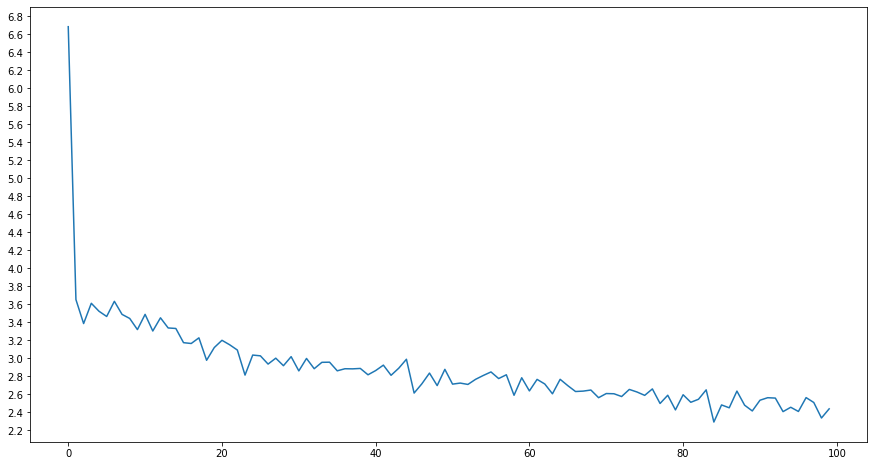

In [ ]:
for iter in range(1, 30001):
    
    training_pair = training_pairs[iter - 1]
    input_tensor = training_pair[0]
    target_tensor = training_pair[1]

    loss = train(input_tensor, target_tensor, 
                 encoder1, decoder1, 
                 encoder_optimizer, decoder_optimizer, 
                 criterion)
    
    print_loss_total += loss
    plot_loss_total += loss

    if iter % 1000 == 0:
        print_loss_avg = print_loss_total / 100
        print_loss_total = 0
        print('iteration - %d loss - %.4f' % (iter, print_loss_avg))

    if iter % 100 == 0:
        plot_loss_avg = plot_loss_total / 100
        plot_losses.append(plot_loss_avg)
        plot_loss_total = 0

fig, ax = plt.subplots(figsize=(15, 8))
loc = ticker.MultipleLocator(base=0.2)
ax.yaxis.set_major_locator(loc)
plt.plot(plot_losses)

KEY: > input = target < output

#### Evaluation
there are no targets so we simply feed the decoder’s predictions back to itself for each step. Every time it predicts a word we add it to the output string, and if it predicts the EOS token we stop there. 

In [ ]:
def evaluate(encoder, decoder, sentence):
    
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence)
        input_length = input_tensor.size(0)
        
        encoder_hidden = encoder.initHidden()

        for ei in range(input_length):
            encoder_output, encoder_hidden = encoder(input_tensor[ei],
                                                     encoder_hidden)

        decoder_input = torch.tensor([[SOS_token]])  
        decoder_hidden = encoder_hidden

        decoded_words = []

        for di in range(MAX_LENGTH):
            decoder_output, decoder_hidden = decoder(decoder_input, 
                                                     decoder_hidden)

            topv, topi = decoder_output.data.topk(1)
            
            if topi.item() == EOS_token:
                decoded_words.append('<EOS>')
                break
                
            else:
                decoded_words.append(output_lang.index2word[topi.item()])

            decoder_input = topi.squeeze().detach()

        return decoded_words

We can evaluate random sentences from the training set and print out the input, target, and output to make some subjective quality judgements:

In [ ]:
for i in range(10):
        
        pair = random.choice(pairs)
        
        print('>', pair[0])
        print('=', pair[1])
        
        output_words = evaluate(encoder1, decoder1, pair[0])
        output_sentence = ' '.join(output_words)
        
        print('<', output_sentence)
        print('')

> so blod bin ich nicht .
= i m not that stupid .
< i m not . . . <EOS>

> ich bin hier weil ich ihre hilfe brauche .
= i m here because i need your help .
< i m sorry i can i can t help .

> ich bin kein bisschen mude .
= i m not at all tired .
< i m not a at all . <EOS>

> er will hoch hinaus .
= he is driven .
< he s a little . . <EOS>

> er lugt .
= he is lying .
< he s a little . <EOS>

> ich spure eine gro e feindseligkeit .
= i m sensing a lot of hostility .
< i m a little . . <EOS>

> das beantwortet meine frage nicht .
= you re not answering my question .
< you re not my . . <EOS>

> die sind alle alter als sie .
= they re all older than you .
< they are as than you . <EOS>

> ich sorge mich um euch alle .
= i m worried about all of you .
< i m going to you you . <EOS>

> du hast den bezug zur realitat verloren .
= you re out of touch with reality .
< you re the only of <EOS>



In [ ]:
input_sentence = 'es tut mir sehr leid' #Re-run for 'es geht mir gut'

In [ ]:
output_words = evaluate(encoder1, 
                        decoder1, 
                        input_sentence)

In [ ]:
print('input =', input_sentence)
print('output =', ' '.join(output_words))

input = es tut mir sehr leid
output = i m sorry about that . <EOS>
